In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "C:\\Users\\Ryan\\Documents\\Berkeley_MFE\\Pre_Program_Courses\\Python\\UCB-MFE-python-preprogram-2026-winter\\Homeworks\\HW2\\Ryan_Beauchamp\\data\\data.db"


In [3]:
import sqlite3
import numpy as np
import pandas as pd

conn = sqlite3.connect(db_path)
df = pd.read_sql_query(
    "SELECT * FROM ohlc_hw_cleaned WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts",
    conn, params=(ticker, start_date, end_date), parse_dates=["ts"])
conn.close()

if len(df) < 21:
    raise ValueError(f"{ticker}: only {len(df)} prices in {start_date} to {end_date}; "
                    "need at least 21 prices for 20 returns")

df = df.set_index("ts")
print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual coverage: {df.index.min().date()} to {df.index.max().date()}")
display(df.head(3))
display(df.tail(3))

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual coverage: 2024-06-03 to 2024-10-18


,ticker,open,high,low,close,adj_close,volume,adj_close_repaired,spike_repaired,volume_repaired,zero_volume_flag,return_outlier_flag
ts,,,,,,,,,,,,
2024-06-03,AAPL,192.90,194.99,192.52,194.03,193.81,50080539,0,0,0,0,0
2024-06-04,AAPL,194.64,195.32,193.03,194.35,194.13,47471445,0,0,0,0,0
2024-06-05,AAPL,195.40,196.90,194.87,195.87,195.64,54156785,0,0,0,0,0


,ticker,open,high,low,close,adj_close,volume,adj_close_repaired,spike_repaired,volume_repaired,zero_volume_flag,return_outlier_flag
ts,,,,,,,,,,,,
2024-10-16,AAPL,231.60,232.12,229.84,231.78,231.78,34082240,0,0,0,0,0
2024-10-17,AAPL,233.43,233.85,230.52,232.15,232.15,32993810,0,0,0,0,0
2024-10-18,AAPL,236.18,236.18,234.01,235.00,235.00,45441281,0,0,0,0,0


In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns, ln(P_t / P_{t-1}). The first value is NaN (no prior price)."""
    return np.log(prices / prices.shift(1))

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Annualized rolling volatility: rolling std of returns * sqrt(252). NaN until `window` returns exist."""
    return returns.rolling(window).std() * np.sqrt(252)

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Per-date drawdown from the running peak: (price - running max) / running max.
    The maximum drawdown for the summary is .min() of this series."""
    running_max = prices.cummax()
    return (prices - running_max) / running_max

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Annualized Sharpe: (mean*252 - rf) / (std*sqrt(252)). NaN if under 2 returns or zero volatility."""
    r = returns.dropna()
    if len(r) < 2:
        return np.nan
    vol = r.std() * np.sqrt(252)
    if not np.isfinite(vol) or vol == 0:
        return np.nan
    return (r.mean() * 252 - risk_free_rate) / vol

In [5]:
price = df["adj_close"]                 # report uses ADJUSTED close
returns = calculate_returns(price)
vol = calculate_volatility(returns)
drawdown = calculate_max_drawdown(price)
ma50 = price.rolling(50).mean()          # NaN until 50 prices exist (not filled with zero)
mean_vol = vol.mean()                    # NaN-skipping mean of the rolling volatility
sharpe = calculate_sharpe_ratio(returns)
max_dd = drawdown.min()

pct = lambda x: "N/A" if pd.isna(x) else f"{x:.2%}"
view = pd.DataFrame({"adj_close": price, "log_return": returns,
                     "vol_20d": vol, "drawdown": drawdown}).tail()
display(pd.DataFrame({"adj_close": view["adj_close"].map("${:,.2f}".format),
                      "log_return": view["log_return"].map(pct),
                      "vol_20d": view["vol_20d"].map(pct),
                      "drawdown": view["drawdown"].map(pct)}))

,adj_close,log_return,vol_20d,drawdown
ts,,,,
2024-10-14,$231.30,1.63%,24.25%,-1.39%
2024-10-15,$233.85,1.10%,24.39%,-0.30%
2024-10-16,$231.78,-0.89%,24.20%,-1.18%
2024-10-17,$232.15,0.16%,20.61%,-1.02%
2024-10-18,$235.00,1.22%,20.95%,0.00%


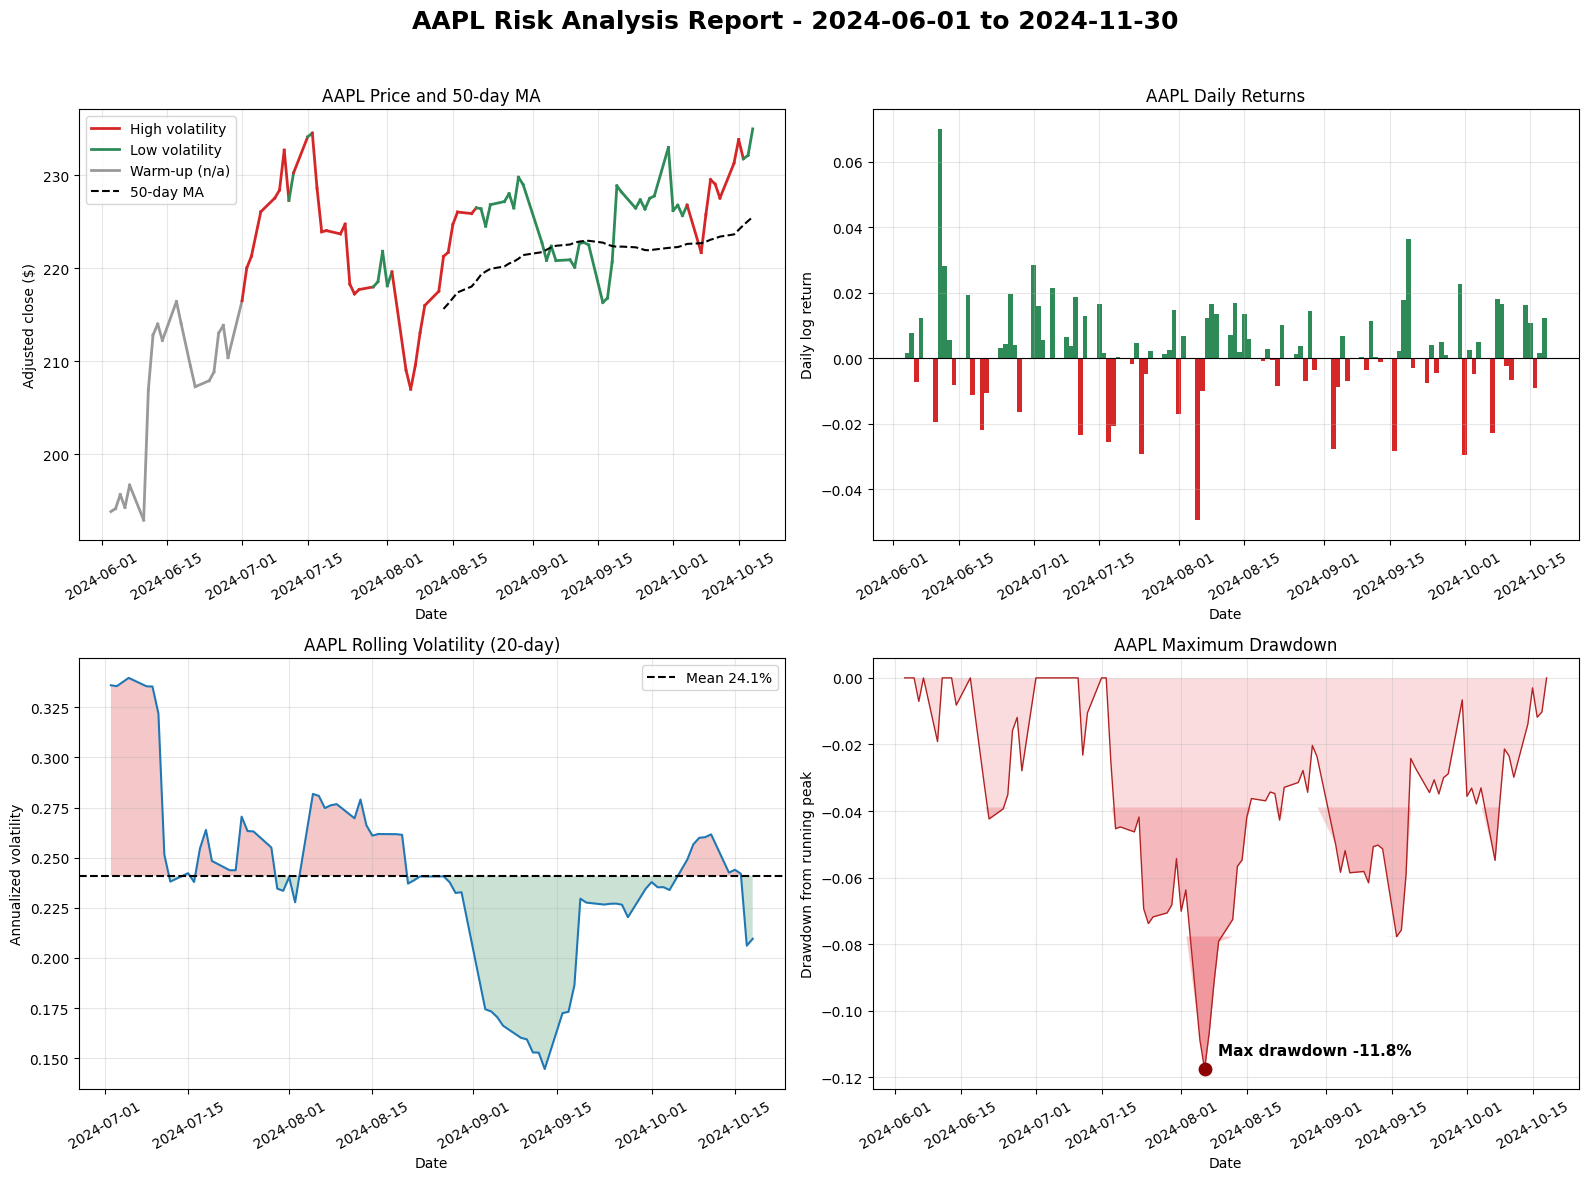

In [6]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

GREEN, RED, GRAY, BLUE = "#2e8b57", "#d62728", "#999999", "#1f77b4"
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")

# Top left: price colored by volatility (gray = warm-up, red = above mean vol, green = otherwise)
ax = axes[0, 0]
for i in range(1, len(price)):
    v = vol.iloc[i]
    color = GRAY if (np.isnan(v) or np.isnan(mean_vol)) else (RED if v > mean_vol else GREEN)
    ax.plot(price.index[i-1:i+1], price.values[i-1:i+1], color=color, linewidth=2)
ma_label = "50-day MA" if ma50.notna().any() else "50-day MA (unavailable: fewer than 50 prices)"
ax.plot(price.index, ma50, color="black", linestyle="--", linewidth=1.5)
ax.legend(handles=[Line2D([0], [0], color=RED, lw=2, label="High volatility"),
                   Line2D([0], [0], color=GREEN, lw=2, label="Low volatility"),
                   Line2D([0], [0], color=GRAY, lw=2, label="Warm-up (n/a)"),
                   Line2D([0], [0], color="black", lw=1.5, ls="--", label=ma_label)], loc="best")
ax.set_title(f"{ticker} Price and 50-day MA"); ax.set_xlabel("Date"); ax.set_ylabel("Adjusted close ($)")

# Top right: daily log returns as green/red bars
ax = axes[0, 1]
rets = returns.dropna()
ax.bar(rets.index, rets.values, color=np.where(rets.values >= 0, GREEN, RED), width=1.0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Daily Returns"); ax.set_xlabel("Date"); ax.set_ylabel("Daily log return")

# Bottom left: rolling volatility, mean line, shaded above/below mean
ax = axes[1, 0]
ax.plot(vol.index, vol, color=BLUE, linewidth=1.5)
if np.isfinite(mean_vol):
    ax.axhline(mean_vol, color="black", linestyle="--", label=f"Mean {mean_vol:.1%}")
    ax.fill_between(vol.index, vol, mean_vol, where=(vol > mean_vol), color=RED, alpha=0.25, interpolate=True, linewidth=0)
    ax.fill_between(vol.index, vol, mean_vol, where=(vol < mean_vol), color=GREEN, alpha=0.25, interpolate=True, linewidth=0)
    ax.legend()
ax.set_title(f"{ticker} Rolling Volatility (20-day)"); ax.set_xlabel("Date"); ax.set_ylabel("Annualized volatility")

# Bottom right: drawdown area with layered red fills (darker = deeper), worst point marked
ax = axes[1, 1]
for frac, alpha in [(0.0, 0.20), (0.33, 0.25), (0.66, 0.30)]:
    level = frac * max_dd
    ax.fill_between(drawdown.index, np.minimum(drawdown.values, level), level,
                    color="#e8505b", alpha=alpha, linewidth=0)
ax.plot(drawdown.index, drawdown, color="#b22222", linewidth=1)
trough = drawdown.idxmin()
ax.scatter([trough], [max_dd], color="darkred", s=80, zorder=5)
ax.annotate(f"Max drawdown {max_dd:.1%}", (trough, max_dd), textcoords="offset points",
            xytext=(10, 10), fontsize=11, fontweight="bold")
ax.set_title(f"{ticker} Maximum Drawdown"); ax.set_xlabel("Date"); ax.set_ylabel("Drawdown from running peak")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [7]:
r = returns.dropna()
n = len(r)
def fmt(x, signed=True):
    if x is None or not np.isfinite(x): return "N/A"
    return f"{x:+.2%}" if signed else f"{x:.2%}"

total_return = price.iloc[-1] / price.iloc[0] - 1
ann_return = np.exp(r.sum() * 252 / n) - 1 if n > 0 else np.nan
ann_vol = r.std() * np.sqrt(252) if n > 1 else np.nan
up, down = r[r > 0], r[r < 0]

summary = pd.DataFrame({
    "Metric": ["Total Return", "Annualized Return", "Annualized Volatility", "Sharpe Ratio",
               "Maximum Drawdown", "Best Day", "Worst Day", "Positive Days",
               "Average Up Day", "Average Down Day"],
    "Value": [fmt(total_return), fmt(ann_return), fmt(ann_vol, signed=False),
              "N/A" if not np.isfinite(sharpe) else f"{sharpe:.2f}",
              fmt(max_dd), fmt(r.max() if n else np.nan), fmt(r.min() if n else np.nan),
              fmt((r > 0).sum() / n if n else np.nan, signed=False),
              fmt(up.mean() if len(up) else np.nan), fmt(down.mean() if len(down) else np.nan)]})
print(summary.to_string(index=False))

# Numbers Part 3 will collect (kept as fractions, not formatted)
report_metrics = {"ticker": ticker, "avg_daily_return": r.mean() if n else np.nan,
                  "avg_volatility": mean_vol, "max_drawdown": max_dd,
                  "sharpe_ratio": sharpe, "total_return": total_return}

               Metric   Value
         Total Return +21.25%
    Annualized Return +65.84%
Annualized Volatility  25.45%
         Sharpe Ratio    1.91
     Maximum Drawdown -11.75%
             Best Day  +7.01%
            Worst Day  -4.94%
        Positive Days  62.50%
       Average Up Day  +1.09%
     Average Down Day  -1.28%


In [8]:
import scrapbook as sb

report_metrics.update(first_date=str(df.index.min().date()),
                      last_date=str(df.index.max().date()), n_days=len(df))
for key, value in report_metrics.items():
    if key == "ticker":
        continue
    if isinstance(value, str):
        sb.glue(key, value)
    else:
        sb.glue(key, None if not np.isfinite(value) else float(value))